# Lab 13 · Drug Exposure y Measurement: distribuciones

Este notebook acompaña a `farmacoepi.sql` y a `reporte_calidad.md`. **No construye nada:** lee las tablas
`results.*` que crea `farmacoepi.sql` y algunas de `cdm`, en una **sesión de solo lectura**, y grafica las
distribuciones. Cada celda tiene `assert` con las cifras del reporte: si el `.sql` cambiara y los números
dejaran de coincidir, el notebook falla en vez de mostrar una figura desactualizada.

**Requisitos:** el Postgres del lab 12 encendido (`docker compose up -d db` en `s12-omop-cdm-introduccion/tu-entrega/`)
y `farmacoepi.sql` ejecutado antes. Entorno: `.venv` con `requirements.txt`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv(Path('../../s12-omop-cdm-introduccion/tu-entrega/.env').resolve())
url = (f"postgresql+psycopg2://{os.environ['POSTGRES_USER']}:{os.environ['POSTGRES_PASSWORD']}"
       f"@localhost:{os.environ['POSTGRES_PORT']}/{os.environ['POSTGRES_DB']}")
# Solo lectura: cualquier INSERT/UPDATE/DROP desde este notebook daría error.
motor = create_engine(url, connect_args={'options': '-c default_transaction_read_only=on'})

def q(sql):
    return pd.read_sql(sql, motor)

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
q('SELECT current_setting(\'transaction_read_only\') AS solo_lectura')

,solo_lectura
0,on


## Actividad 2 · Distribución de `days_supply` (prescripciones)

`days_supply` cruda (decisión 4), solo `drug_type_concept_id = 32838`. Las dos pilas son artefactos:
**0 días** (fin = inicio, sobre todo recetas en curso que el ETL cerró en su fecha de inicio) y **371 días**
(renovación anual de los tratamientos crónicos en Synthea).

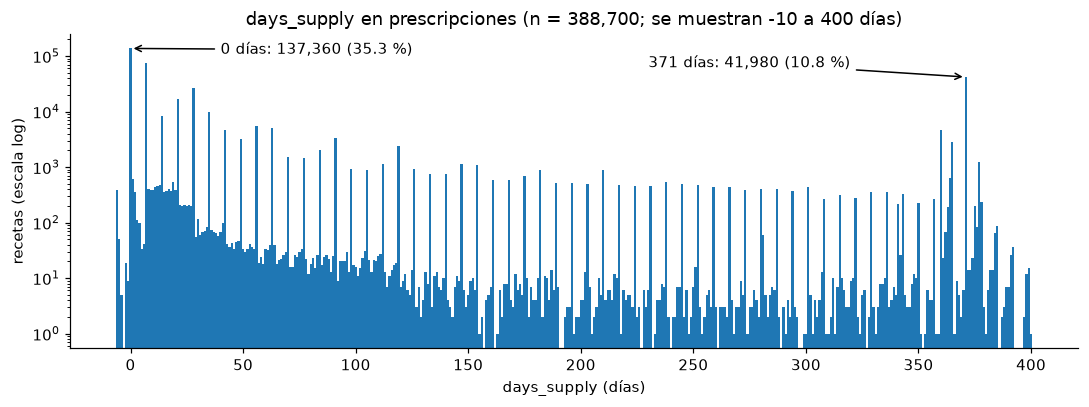

In [2]:
ds = q('''
    SELECT days_supply, count(*) AS recetas
    FROM cdm.drug_exposure
    WHERE drug_type_concept_id = 32838
    GROUP BY days_supply ORDER BY days_supply''')
total = ds.recetas.sum()
n = dict(zip(ds.days_supply, ds.recetas))
assert total == 388_700, total
assert n[0] == 137_360 and n[371] == 41_980, (n[0], n[371])
assert ds.loc[ds.days_supply < 0, 'recetas'].sum() == 479

fig, ax = plt.subplots(figsize=(10, 3.8))
ver = ds[ds.days_supply.between(-10, 400)]
ax.bar(ver.days_supply, ver.recetas, width=1.0, color='tab:blue')
ax.set(yscale='log', xlabel='days_supply (días)', ylabel='recetas (escala log)',
       title=f'days_supply en prescripciones (n = {total:,}; se muestran -10 a 400 días)')
ax.annotate(f'0 días: {n[0]:,} (35.3 %)', (0, n[0]), xytext=(40, n[0] * 0.8), arrowprops={'arrowstyle': '->'})
ax.annotate(f'371 días: {n[371]:,} (10.8 %)', (371, n[371]), xytext=(230, n[371] * 1.5), arrowprops={'arrowstyle': '->'})
plt.tight_layout(); plt.show()

La parte plausible (1-365 días) tiene picos en **múltiplos de 7 días** (7 días: 74,741 recetas; 28: 26,694; 21: 16,746),
que reflejan envases semanales. Las dos
pilas concentran el 46 % de las recetas y **no son duraciones clínicas**. Por eso en las actividades 4-5 no se usó
`days_supply` tal cual: se aplicaron las reglas de eras de OHDSI y un supuesto explícito para las recetas en curso.

## Actividad 4 · Duración de las eras de lisinopril: propias contra `cdm.drug_era`

Eras construidas a mano con gaps and islands (gap de 30 días, reglas OHDSI sin acumulación) frente a la tabla
derivada que trae el ETL.

              count  median
fuente                     
cdm.drug_era   1541  3633.0
propia         1541  3633.0 
eras de 0 días: 116


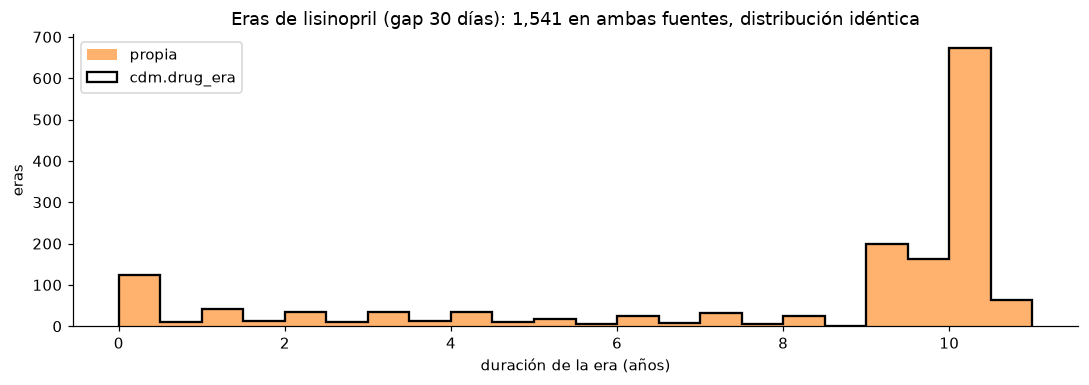

In [3]:
eras = q('''
    SELECT 'propia' AS fuente, drug_era_end_date - drug_era_start_date AS dias
    FROM results.lisinopril_era
    UNION ALL
    SELECT 'cdm.drug_era', drug_era_end_date - drug_era_start_date
    FROM cdm.drug_era WHERE drug_concept_id = 1308216''')
cnt = eras.groupby('fuente').dias.agg(['count', 'median'])
assert (cnt['count'] == 1_541).all(), cnt
assert (eras[eras.fuente == 'propia'].dias.sort_values().values ==
        eras[eras.fuente == 'cdm.drug_era'].dias.sort_values().values).all()   # misma distribución
cero = (eras[eras.fuente == 'propia'].dias == 0).sum()
print(cnt, f'\neras de 0 días: {cero}')

fig, ax = plt.subplots(figsize=(10, 3.6))
bins = np.arange(0, 11.5, 0.5)   # máximo observado: 11 años
for fuente, estilo in [('propia', {'color': 'tab:orange', 'alpha': 0.6}),
                       ('cdm.drug_era', {'histtype': 'step', 'color': 'black', 'lw': 1.5})]:
    ax.hist(eras[eras.fuente == fuente].dias / 365.25, bins=bins, label=fuente, **estilo)
ax.set(xlabel='duración de la era (años)', ylabel='eras',
       title='Eras de lisinopril (gap 30 días): 1,541 en ambas fuentes, distribución idéntica')
ax.legend(); plt.tight_layout(); plt.show()

Las dos distribuciones se superponen exactamente (el `assert` lo comprueba valor a valor). Casi todos los
pacientes tienen **una sola era de años**: el encadenamiento de recetas de Synthea no deja huecos. Las eras de
0 días corresponden a recetas en curso que el ETL dejó con duración cero.

## Actividad 5 · PDC principal, sensibilidad y MPR

Cohorte de 1,461 pacientes con un año completo de seguimiento tras la primera receta. MPR calculado igual que en
el trozo 5c: suma de `days_supply` de las recetas que empiezan en la ventana, dividida entre 365.

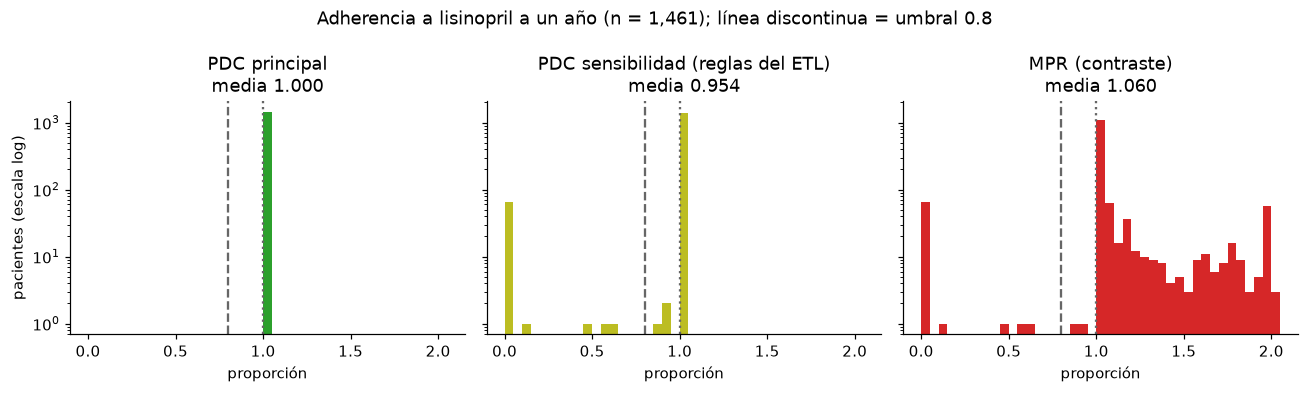

In [4]:
adh = q('''
    WITH mpr AS (
        SELECT c.person_id, coalesce(sum(x.days_supply), 0) / 365.0 AS mpr
        FROM results.lisinopril_pdc_cohorte c
        LEFT JOIN results.lisinopril_exposicion x
          ON x.person_id = c.person_id AND x.inicio BETWEEN c.fecha_indice AND c.fin_ventana
        WHERE c.seguimiento_1_anio
        GROUP BY c.person_id)
    SELECT p.person_id, p.pdc, p.pdc_sensibilidad, m.mpr
    FROM results.lisinopril_pdc p JOIN mpr m USING (person_id)''').astype({'pdc': float, 'pdc_sensibilidad': float, 'mpr': float})
assert len(adh) == 1_461
assert round(adh.pdc.mean(), 3) == 1.000
assert round(adh.pdc_sensibilidad.mean(), 3) == 0.954 and (adh.pdc_sensibilidad == 0).sum() == 65
assert round(adh.mpr.mean(), 3) == 1.060 and (adh.mpr > 1).sum() == 1_390

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
bins = np.arange(0, 2.1, 0.05)
for ax, col, titulo, color in zip(axes, ['pdc', 'pdc_sensibilidad', 'mpr'],
                                  ['PDC principal', 'PDC sensibilidad (reglas del ETL)', 'MPR (contraste)'],
                                  ['tab:green', 'tab:olive', 'tab:red']):
    ax.hist(adh[col], bins=bins, color=color)
    ax.axvline(0.8, ls='--', c='0.4'); ax.axvline(1.0, ls=':', c='0.4')
    ax.set(title=f'{titulo}\nmedia {adh[col].mean():.3f}', xlabel='proporción', yscale='log')
axes[0].set_ylabel('pacientes (escala log)')
fig.suptitle('Adherencia a lisinopril a un año (n = 1,461); línea discontinua = umbral 0.8')
plt.tight_layout(); plt.show()

- **PDC principal:** todos en 1.0, artefacto del encadenamiento de recetas (no es un hallazgo clínico).
- **Sensibilidad:** con las reglas del ETL (recetas en curso = 0 días) aparecen **65 pacientes con PDC = 0** que
  siguen en tratamiento. Un solo supuesto mueve el porcentaje de adherentes de 100 % a 95.3 %.
- **MPR:** 1,390 pacientes por encima de 1 (una receta de 371 días da 371/365 = 1.016). El PDC está acotado en
  [0, 1] y el MPR no: por eso se usó el PDC.

## Actividad 7 · Globulina antes y después de normalizar a g/L

Misma figura que `figura_globulina.py`. Bins con la resolución de los datos (0.1 antes, 1 después) y eje
logarítmico compartido: 20,412 frente a 16 filas no se verían en escala lineal.

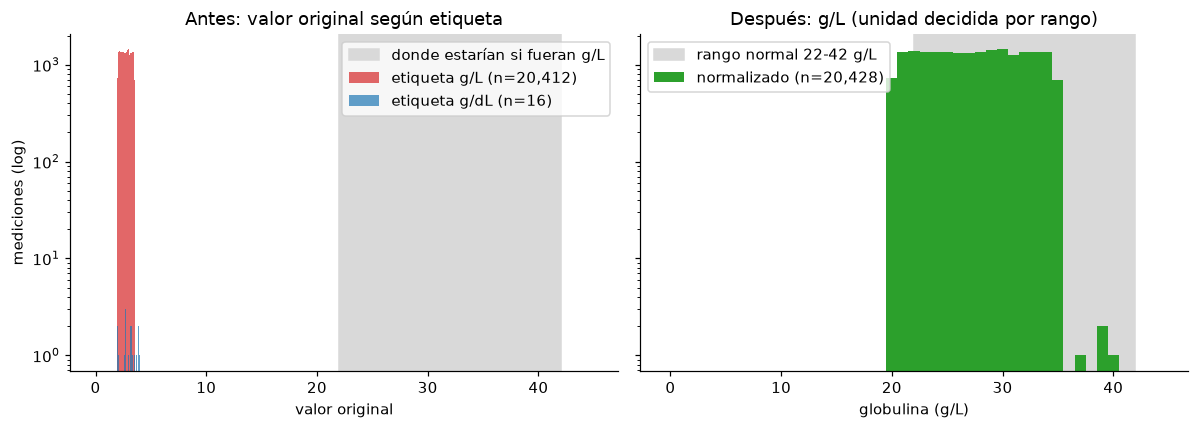

In [5]:
glo = q('SELECT valor_original, unidad_original_texto, valor_g_l, regla_aplicada FROM results.globulina_normalizada').astype(
    {'valor_original': float, 'valor_g_l': float})
assert len(glo) == 20_428 and (glo.regla_aplicada == 'reetiquetada_por_rango').sum() == 20_412

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
a1.axvspan(22, 42, color='0.85', label='donde estarían si fueran g/L')
for u, c in [('g/L', 'tab:red'), ('g/dL', 'tab:blue')]:
    s = glo.loc[glo.unidad_original_texto == u, 'valor_original']
    a1.hist(s, bins=np.arange(-0.05, 45.05, 0.1), alpha=0.7, color=c, label=f'etiqueta {u} (n={len(s):,})')
a1.set(title='Antes: valor original según etiqueta', xlabel='valor original', ylabel='mediciones (log)', yscale='log')
a1.legend()
a2.axvspan(22, 42, color='0.85', label='rango normal 22-42 g/L')
a2.hist(glo.valor_g_l, bins=np.arange(-0.5, 45.5, 1), color='tab:green', label=f'normalizado (n={len(glo):,})')
a2.set(title='Después: g/L (unidad decidida por rango)', xlabel='globulina (g/L)', yscale='log')
a2.legend(loc='upper left'); plt.tight_layout(); plt.show()

Antes, las dos etiquetas caen en 2-4: la etiqueta g/L está mal en origen. Después hay una sola escala (20-40 g/L).
La distribución es **plana**, no una campana: Synthea genera el valor de forma uniforme en un rango fijo.

## Actividad 8 · Valores implausibles: HbA1c y creatinina

Rangos citados en `results.criterios_plausibilidad` (HbA1c 3.5-20 %, manual de NHANES; creatinina 0.1-5 mg/dL,
OHDSI DQD). Clasificación de `results.measurement_plausibilidad`.

analito     clasificacion              
Creatinina  dentro_rango                   63879
            extremo_real_contexto_renal     2985
            revisar_contexto_posterior      1103
            revisar_sin_contexto            1139
HbA1c       dentro_rango                   35484
            implausible_metodo             23485
dtype: int64


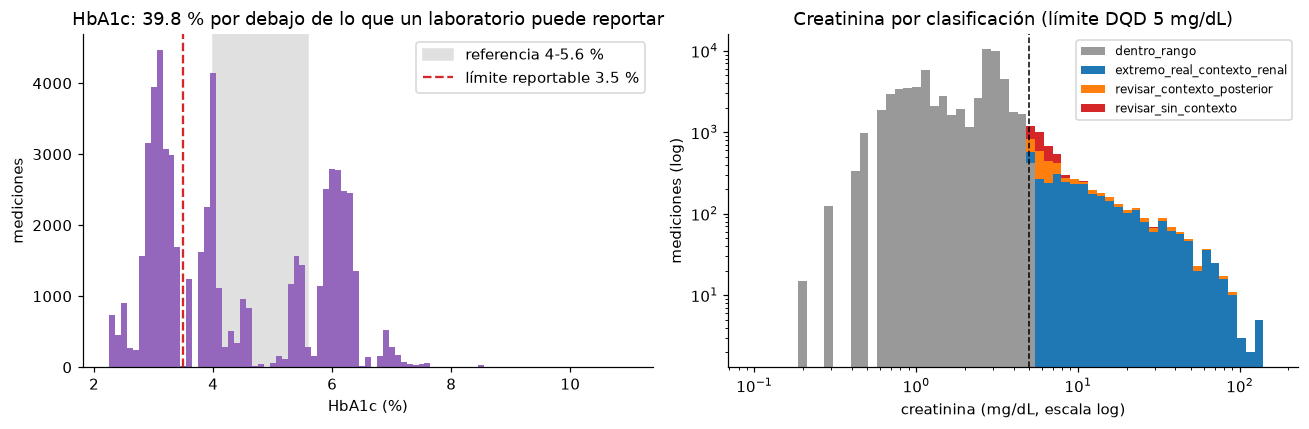

In [6]:
mp = q('''
    SELECT analito, clasificacion, valor_original
    FROM results.measurement_plausibilidad
    WHERE analito IN ('HbA1c', 'Creatinina')''').astype({'valor_original': float})
cl = mp.groupby(['analito', 'clasificacion']).size()
assert cl['HbA1c', 'implausible_metodo'] == 23_485
assert (cl['Creatinina', 'extremo_real_contexto_renal'], cl['Creatinina', 'revisar_contexto_posterior'],
        cl['Creatinina', 'revisar_sin_contexto']) == (2_985, 1_103, 1_139)
print(cl)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
h = mp[mp.analito == 'HbA1c']
a1.axvspan(4, 5.6, color='0.88', label='referencia 4-5.6 %')
a1.hist(h.valor_original, bins=np.arange(2.25, 11.05, 0.1), color='tab:purple')
a1.axvline(3.5, c='tab:red', ls='--', label='límite reportable 3.5 %')
a1.set(title='HbA1c: 39.8 % por debajo de lo que un laboratorio puede reportar',
       xlabel='HbA1c (%)', ylabel='mediciones'); a1.legend()

cr = mp[mp.analito == 'Creatinina']
orden = ['dentro_rango', 'extremo_real_contexto_renal', 'revisar_contexto_posterior', 'revisar_sin_contexto']
colores = ['0.6', 'tab:blue', 'tab:orange', 'tab:red']
a2.hist([cr.loc[cr.clasificacion == k, 'valor_original'] for k in orden], bins=np.logspace(-1, 2.2, 60),
        stacked=True, color=colores, label=orden)
a2.axvline(5, c='k', ls='--', lw=1)
a2.set(xscale='log', yscale='log', title='Creatinina por clasificación (límite DQD 5 mg/dL)',
       xlabel='creatinina (mg/dL, escala log)', ylabel='mediciones (log)'); a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

- **HbA1c:** la mitad baja de la distribución está fuera del rango reportable. No son valores atípicos sueltos:
  se concentran en 485 pacientes (276 con todas sus HbA1c bajas), lo que apunta al generador. Se pasan a NULL
  en `valor_analitico` y se conserva el original.
- **Creatinina:** por encima de 5 mg/dL dominan los pacientes con contexto renal previo (extremos reales). Los
  valores sin contexto o con contexto solo posterior quedan marcados para revisión, no se borran.

## Actividad 10 · Creatinina basal: días respecto al inicio de lisinopril

Valor más cercano al índice (primera receta). Política A: [−90, 0], principal. Política B: ±90, contraste.

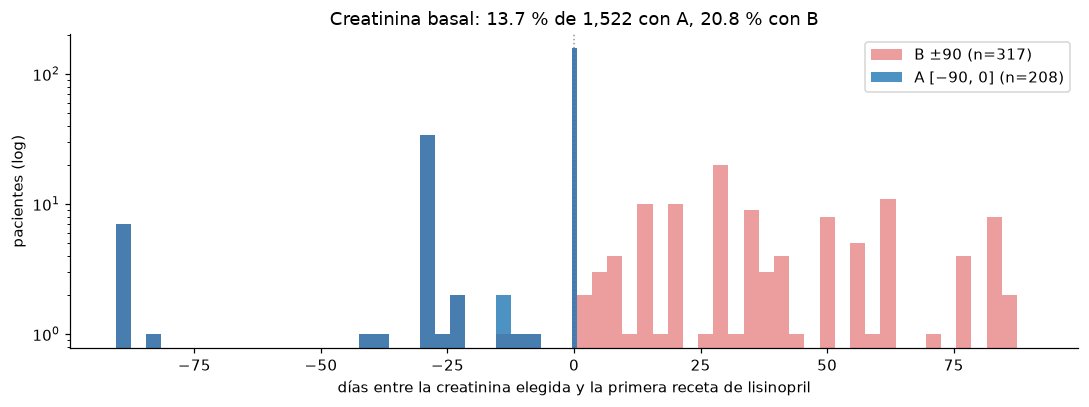

Sin valor basal (A): 1,314 de 1,522


In [7]:
cb = q('SELECT dias_a, dias_b, creat_a FROM results.creatinina_basal')
assert len(cb) == 1_522
assert cb.dias_a.notna().sum() == 208 and cb.dias_b.notna().sum() == 317
assert (cb.dias_b > 0).sum() == 110 and (cb.dias_a == 0).sum() == 157

fig, ax = plt.subplots(figsize=(10, 3.8))
# día 0 con bin propio para que los posteriores (B) no se mezclen con él
bins = np.r_[np.arange(-90.5, -0.4, 3), 0.5, np.arange(3.5, 91, 3)]
ax.hist(cb.dias_b.dropna(), bins=bins, color='tab:red', alpha=0.45, label=f'B ±90 (n={cb.dias_b.notna().sum()})')
ax.hist(cb.dias_a.dropna(), bins=bins, color='tab:blue', alpha=0.8, label=f'A [−90, 0] (n={cb.dias_a.notna().sum()})')
ax.axvline(0, c='0.6', ls=':', lw=1, zorder=0)   # detrás de las barras: no tapa el día 0
ax.set(yscale='log', xlabel='días entre la creatinina elegida y la primera receta de lisinopril',
       ylabel='pacientes (log)', title='Creatinina basal: 13.7 % de 1,522 con A, 20.8 % con B')
ax.legend(); plt.tight_layout(); plt.show()
print(f'Sin valor basal (A): {cb.creat_a.isna().sum():,} de {len(cb):,}')

Tres cuartas partes de las basales de A son del **día 0** (el análisis de la consulta en la que se prescribe).
Todo lo que B añade a la derecha del 0 son valores medidos **con el fármaco ya iniciado**: fuga de información.
La cobertura de la política A (**13.7 %**) es la que limitará la cohorte de la sesión 17 si se exige función renal
basal.